# Simulación de la degradación de una máquina rotativa con un HMM discreto
**Asignatura:** Simulación · Módulo 2, Actividad didáctica 2

Todos los datos de este cuaderno son **sintéticos**. Los parámetros de las matrices son hipótesis de diseño, no estimaciones de una máquina real.

**Cómo usarlo:** ejecuta las celdas en orden (Entorno de ejecución → Ejecutar todo, o una por una). La celda 8 es la más lenta (unos minutos).

## Celda 1. Librerías y configuración global
Aquí se fijan todos los parámetros del experimento en un único diccionario (`CONFIG`), para que cualquiera pueda reproducir el trabajo cambiando solo este bloque.
- `T`: instantes por trayectoria. `R`: réplicas por escenario.
- `SEMILLA_BASE`: la réplica `r` usa la semilla `SEMILLA_BASE + r`.
- `SEMILLAS_REPRO`: cinco semillas base separadas por 10 000 para que sus rangos de réplicas no se solapen (así las cinco repeticiones son independientes).

In [ ]:
import os, sys, time, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

CONFIG = {
    "T": 100,                      # instantes de tiempo por trayectoria
    "R": 1000,                     # réplicas por escenario
    "SEMILLA_BASE": 10000,         # semilla base del experimento principal
    "SEMILLAS_REPRO": [10000, 20000, 30000, 40000, 50000],  # repeticiones completas
    "NIVEL_CONF": 0.95,            # nivel de confianza de los intervalos
    "DPI": 300,                    # resolución de las figuras
    "CARPETA": "resultados",       # carpeta donde se guardan tablas y figuras
}
os.makedirs(CONFIG["CARPETA"], exist_ok=True)

NOMBRES_ESTADOS = ["S1 Normal", "S2 Moderada", "S3 Crítica"]
NOMBRES_OBS = ["V1 Baja", "V2 Media", "V3 Alta"]

plt.rcParams.update({"savefig.dpi": CONFIG["DPI"], "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})
print("Configuración cargada:", CONFIG)

Configuración cargada: {'T': 100, 'R': 1000, 'SEMILLA_BASE': 10000, 'SEMILLAS_REPRO': [10000, 20000, 30000, 40000, 50000], 'NIVEL_CONF': 0.95, 'DPI': 300, 'CARPETA': 'resultados'}


## Celda 2. Definición del modelo y de los escenarios
Se construyen π, A y B de cada escenario. Cada escenario es un diccionario con:
- `A`, `B`, `pi`: parámetros con los que se **generan** los datos.
- `B_dec`: la matriz de emisión que usa **Viterbi** para decodificar. Es igual a `B` en todos los escenarios salvo E6 (modelo mal especificado), donde los datos se generan con la B de E0 pero se decodifican con la B de E3.

La estructura de A es triangular superior con S3 absorbente: la degradación solo avanza y no hay reparación espontánea.

In [ ]:
def matriz_A(a12, a23):
    """Matriz de transición con degradación en una sola dirección y S3 absorbente."""
    return np.array([[1 - a12, a12,      0.0],
                     [0.0,     1 - a23,  a23],
                     [0.0,     0.0,      1.0]])

# Matrices de emisión (filas = estado oculto, columnas = vibración baja/media/alta)
B_BASE = np.array([[0.80, 0.18, 0.02],
                   [0.20, 0.60, 0.20],
                   [0.02, 0.18, 0.80]])
B_POCO = np.array([[0.50, 0.30, 0.20],      # poco informativa
                   [0.30, 0.40, 0.30],
                   [0.20, 0.30, 0.50]])
B_MUY = np.array([[0.95, 0.04, 0.01],       # muy informativa
                  [0.05, 0.90, 0.05],
                  [0.01, 0.04, 0.95]])

PI_BASE = np.array([1.0, 0.0, 0.0])
PI_PARCIAL = np.array([0.6, 0.4, 0.0])

ESCENARIOS = {
    "E0": dict(desc="Base",                      A=matriz_A(0.05, 0.10), B=B_BASE, pi=PI_BASE,    B_dec=B_BASE),
    "E1": dict(desc="Degradación rápida",        A=matriz_A(0.10, 0.20), B=B_BASE, pi=PI_BASE,    B_dec=B_BASE),
    "E2": dict(desc="Degradación lenta",         A=matriz_A(0.02, 0.05), B=B_BASE, pi=PI_BASE,    B_dec=B_BASE),
    "E3": dict(desc="Emisión poco informativa",  A=matriz_A(0.05, 0.10), B=B_POCO, pi=PI_BASE,    B_dec=B_POCO),
    "E4": dict(desc="Emisión muy informativa",   A=matriz_A(0.05, 0.10), B=B_MUY,  pi=PI_BASE,    B_dec=B_MUY),
    "E5": dict(desc="Inicio parcialmente degradado", A=matriz_A(0.05, 0.10), B=B_BASE, pi=PI_PARCIAL, B_dec=B_BASE),
    "E6": dict(desc="Modelo mal especificado",   A=matriz_A(0.05, 0.10), B=B_BASE, pi=PI_BASE,    B_dec=B_POCO),
}

print("Matriz A del escenario base (E0):\n", ESCENARIOS["E0"]["A"])
print("Matriz B del escenario base (E0):\n", ESCENARIOS["E0"]["B"])
print("π de E0:", ESCENARIOS["E0"]["pi"])

Matriz A del escenario base (E0):
 [[0.95 0.05 0.  ]
 [0.   0.9  0.1 ]
 [0.   0.   1.  ]]
Matriz B del escenario base (E0):
 [[0.8  0.18 0.02]
 [0.2  0.6  0.2 ]
 [0.02 0.18 0.8 ]]
π de E0: [1. 0. 0.]


## Celda 3. Validación del modelo y valores teóricos
Antes de simular se comprueba que las matrices sean válidas (filas que suman 1, sin retrocesos, S3 absorbente).

Después se calculan valores **teóricos exactos** con álgebra de Markov, que más tarde servirán para validar la simulación:
- `P(τ ≤ T)`: probabilidad de haber alcanzado S3 en el horizonte. Como S3 es absorbente, coincide con `P(X_T = S3) = (π A^(T-1))[S3]`.
- `E[τ]` sin truncar: `1 + π_transitorios · M · 1`, con `M = (I − Q)^(-1)` (matriz fundamental).
- `E[τ | τ ≤ T]`: media de τ condicionada a que ocurra dentro de T. Es el valor comparable con la media simulada, porque en la simulación solo se promedian las réplicas no censuradas.
- Frecuencia esperada de permanencia en cada estado dentro de T.

Esto **no es un resultado de simulación**: sale de las matrices.

In [ ]:
def validar_modelo(A, B, pi):
    assert A.shape == (3, 3) and B.shape == (3, 3) and pi.shape == (3,)
    assert (A >= 0).all() and (B >= 0).all() and (pi >= 0).all()
    assert np.allclose(A.sum(axis=1), 1) and np.allclose(B.sum(axis=1), 1) and np.isclose(pi.sum(), 1)
    assert np.allclose(np.tril(A, -1), 0), "A no debe permitir retrocesos"
    assert A[2, 2] == 1.0, "S3 debe ser absorbente"

def teoria(A, pi, T):
    """Cantidades exactas del modelo (sin simular)."""
    dist = np.zeros((T, 3))            # dist[t-1] = distribución de X_t
    dist[0] = pi
    for t in range(1, T):
        dist[t] = dist[t - 1] @ A
    F = dist[:, 2]                      # P(τ ≤ t) porque S3 es absorbente
    p_crit = F[-1]
    pmf = np.diff(np.concatenate([[0.0], F]))      # P(τ = t)
    t_vals = np.arange(1, T + 1)
    tau_trunc = (t_vals * pmf).sum() / p_crit if p_crit > 0 else np.nan
    Q = A[:2, :2]
    M = np.linalg.inv(np.eye(2) - Q)
    tau_inf = 1 + pi[:2] @ M @ np.ones(2)
    return {"p_crit": p_crit, "tau_trunc": tau_trunc, "tau_inf": tau_inf,
            "freq": dist.mean(axis=0)}

TEORIA = {}
for nombre, e in ESCENARIOS.items():
    validar_modelo(e["A"], e["B"], e["pi"])
    validar_modelo(e["A"], e["B_dec"], e["pi"])
    TEORIA[nombre] = teoria(e["A"], e["pi"], CONFIG["T"])

print("Validación estructural superada en todos los escenarios.\n")
print("Valores teóricos (no son resultados de simulación):")
print(pd.DataFrame({k: {"P(τ≤T)": v["p_crit"], "E[τ] sin truncar": v["tau_inf"],
                        "E[τ | τ≤T]": v["tau_trunc"]} for k, v in TEORIA.items()}).T.round(4))

Validación estructural superada en todos los escenarios.

Valores teóricos (no son resultados de simulación):
    P(τ≤T)  E[τ] sin truncar  E[τ | τ≤T]
E0  0.9876              31.0     29.8791
E1  0.9999              16.0     15.9945
E2  0.7786              71.0     48.3772
E3  0.9876              31.0     29.8791
E4  0.9876              31.0     29.8791
E5  0.9925              23.0     22.2696
E6  0.9876              31.0     29.8791


## Celda 4. Simulación de una trayectoria (estados ocultos y observaciones)
Se usa el método de la transformada inversa: se sortea un número uniforme `u` y se elige el primer estado cuya probabilidad acumulada supera `u`. Las filas de π, A y B son distribuciones categóricas, de modo que este es el muestreo categórico del marco teórico.

Cada réplica usa su propio generador `default_rng(semilla)` y consume siempre los mismos números uniformes. Por eso **todos los escenarios comparten los mismos números aleatorios** (números aleatorios comunes). Dos consecuencias:
- Las comparaciones entre escenarios son pareadas y tienen menos varianza.
- Los escenarios que no cambian ni A ni π (E0, E3, E4, E6) generan **exactamente las mismas trayectorias de estados**. Solo cambian las observaciones y la decodificación. Por tanto, probabilidad crítica, τ y frecuencias de permanencia saldrán idénticas en esos cuatro escenarios, y lo único que los distingue es la exactitud.

In [ ]:
def simular_estados(A, pi, T, u):
    cumA = np.cumsum(A, axis=1); cumA[:, -1] = 1.0
    cumpi = np.cumsum(pi);       cumpi[-1] = 1.0
    x = np.empty(T, dtype=int)
    x[0] = np.searchsorted(cumpi, u[0], side="right")
    for t in range(1, T):
        x[t] = np.searchsorted(cumA[x[t - 1]], u[t], side="right")
    return x

def simular_observaciones(B, x, u):
    cumB = np.cumsum(B, axis=1); cumB[:, -1] = 1.0
    return (u[:, None] >= cumB[x]).sum(axis=1)

def simular_replica(esc, T, semilla):
    rng = np.random.default_rng(semilla)
    u_estados = rng.random(T)
    u_obs = rng.random(T)
    x = simular_estados(esc["A"], esc["pi"], T, u_estados)
    o = simular_observaciones(esc["B"], x, u_obs)
    return x, o

# Prueba rápida con la primera réplica del escenario base
x_demo, o_demo = simular_replica(ESCENARIOS["E0"], 20, CONFIG["SEMILLA_BASE"])
print("Estados ocultos (0=S1, 1=S2, 2=S3):", x_demo)
print("Vibración observada (0=baja, 1=media, 2=alta):", o_demo)

Estados ocultos (0=S1, 1=S2, 2=S3): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Vibración observada (0=baja, 1=media, 2=alta): [0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]


## Celda 5. Algoritmos Forward y Viterbi
Ambos están implementados a mano con NumPy.
- **Viterbi** trabaja con logaritmos para evitar desbordamiento numérico. Con `np.errstate` se tolera `log 0 = −∞`, necesario porque A tiene ceros. Devuelve la secuencia de estados más probable y el logaritmo de su probabilidad.
- **Forward** usa escalamiento por pasos para calcular `log P(o | λ)`. Se usa como control: la probabilidad del mejor camino de Viterbi nunca puede superar la verosimilitud total.

In [ ]:
def viterbi(obs, A, B, pi):
    T = len(obs)
    with np.errstate(divide="ignore"):
        logA, logB, logpi = np.log(A), np.log(B), np.log(pi)
    delta = np.empty((T, 3)); psi = np.zeros((T, 3), dtype=int)
    delta[0] = logpi + logB[:, obs[0]]
    for t in range(1, T):
        puntajes = delta[t - 1][:, None] + logA          # puntajes[i, j]: venir de i hacia j
        psi[t] = puntajes.argmax(axis=0)
        delta[t] = puntajes.max(axis=0) + logB[:, obs[t]]
    camino = np.empty(T, dtype=int)
    camino[-1] = delta[-1].argmax()
    for t in range(T - 2, -1, -1):                       # reconstrucción hacia atrás
        camino[t] = psi[t + 1][camino[t + 1]]
    return camino, delta[-1].max()

def forward_loglik(obs, A, B, pi):
    alpha = pi * B[:, obs[0]]
    c = alpha.sum(); ll = np.log(c); alpha = alpha / c
    for t in range(1, len(obs)):
        alpha = (alpha @ A) * B[:, obs[t]]
        c = alpha.sum(); ll += np.log(c); alpha = alpha / c
    return ll

# Prueba con la réplica de demostración
esc0 = ESCENARIOS["E0"]
x_est, logp_vit = viterbi(o_demo, esc0["A"], esc0["B_dec"], esc0["pi"])
ll_fwd = forward_loglik(o_demo, esc0["A"], esc0["B_dec"], esc0["pi"])
print("Estados reales:     ", x_demo)
print("Estados por Viterbi:", x_est)
print(f"log P(camino Viterbi) = {logp_vit:.3f}  ≤  log P(obs | λ) = {ll_fwd:.3f}  →", logp_vit <= ll_fwd + 1e-9)

Estados reales:      [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Estados por Viterbi: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
log P(camino Viterbi) = -8.421  ≤  log P(obs | λ) = -8.404  → True


## Celda 6. Métricas por réplica y ejecución de un escenario
Para cada réplica se calculan:
- `alcanza_real`: si el estado real llegó a S3 dentro de T. `tau`: primer instante en S3 (vacío si hay censura).
- `freq_S1..S3`: proporción de instantes en cada estado real.
- `acc_global` y `acc_S1..S3`: exactitud de Viterbi global y por estado (vacía si ese estado no aparece en la réplica).
- `alcanza_est` y `tau_est`: lo mismo, pero según el estado decodificado.
- `retraso`: `tau_est − tau` cuando ambos existen. Un valor positivo significa que Viterbi detecta el estado crítico después de que ocurre.

Además, en cada réplica se verifica la coherencia Viterbi ≤ Forward.

In [ ]:
def primer_instante(secuencia, estado=2):
    idx = np.flatnonzero(secuencia == estado)
    return float(idx[0] + 1) if idx.size else np.nan     # instantes numerados desde 1

def evaluar_replica(x, x_est, T):
    tau, tau_est = primer_instante(x), primer_instante(x_est)
    fila = {"alcanza_real": not np.isnan(tau), "tau": tau,
            "alcanza_est": not np.isnan(tau_est), "tau_est": tau_est,
            "retraso": tau_est - tau,                      # NaN si falta alguno
            "acc_global": float((x == x_est).mean())}
    conteo = np.bincount(x, minlength=3) / T
    for s in range(3):
        fila[f"freq_S{s+1}"] = conteo[s]
        fila[f"acc_S{s+1}"] = float((x_est[x == s] == s).mean()) if (x == s).any() else np.nan
    return fila

def correr_escenario(nombre, esc, semilla_base, R, T):
    filas = []
    for r in range(R):
        x, o = simular_replica(esc, T, semilla_base + r)
        x_est, logp = viterbi(o, esc["A"], esc["B_dec"], esc["pi"])
        ll = forward_loglik(o, esc["A"], esc["B_dec"], esc["pi"])
        assert logp <= ll + 1e-9, "Viterbi no puede superar a Forward"
        fila = evaluar_replica(x, x_est, T)
        fila.update({"escenario": nombre, "semilla_base": semilla_base, "replica": r})
        filas.append(fila)
    return pd.DataFrame(filas)

# Prueba con pocas réplicas
print(correr_escenario("E0", ESCENARIOS["E0"], CONFIG["SEMILLA_BASE"], 5, CONFIG["T"]).round(3))

   alcanza_real   tau  alcanza_est  tau_est  retraso  acc_global  freq_S1  \
0          True  49.0         True     46.0     -3.0        0.96     0.21   
1          True  11.0         True     11.0      0.0        0.98     0.07   
2          True  22.0         True     22.0      0.0        1.00     0.12   
3          True  23.0         True     25.0      2.0        0.98     0.02   
4         False   NaN        False      NaN      NaN        1.00     1.00   

   acc_S1  freq_S2  acc_S2  freq_S3  acc_S3 escenario  semilla_base  replica  
0     1.0     0.27   0.852     0.52   1.000        E0         10000        0  
1     1.0     0.03   0.333     0.90   1.000        E0         10000        1  
2     1.0     0.09   1.000     0.79   1.000        E0         10000        2  
3     1.0     0.20   1.000     0.78   0.974        E0         10000        3  
4     1.0     0.00     NaN     0.00     NaN        E0         10000        4  


## Celda 7. Funciones estadísticas
- **Intervalo t de Student** al 95 % para medias entre réplicas (ignora los vacíos). Se usa para τ, frecuencias, exactitud y retraso. En exactitudes y frecuencias, que son proporciones, el límite se acota a [0, 1] (`acotar=True`).
- **Intervalo de Wilson** al 95 % para proporciones (probabilidad de alcanzar S3, tasa de detección y de falsas alarmas). Se prefiere al de Wald porque se comporta mejor cerca de 0 y 1.

In [ ]:
def ic_t(valores, nivel=CONFIG["NIVEL_CONF"], acotar=False):
    x = np.asarray(valores, dtype=float); x = x[~np.isnan(x)]
    n = len(x)
    if n < 2:
        return dict(media=np.nan, sd=np.nan, inf=np.nan, sup=np.nan, n=n)
    m, s = x.mean(), x.std(ddof=1)
    h = stats.t.ppf(0.5 + nivel / 2, n - 1) * s / np.sqrt(n)
    inf, sup = m - h, m + h
    if acotar:                       # exactitudes y frecuencias son proporciones: el IC se acota a [0, 1]
        inf, sup = max(0.0, inf), min(1.0, sup)
    return dict(media=m, sd=s, inf=inf, sup=sup, n=n)

def wilson(k, n, nivel=CONFIG["NIVEL_CONF"]):
    if n == 0:
        return dict(p=np.nan, inf=np.nan, sup=np.nan, n=0)
    z = stats.norm.ppf(0.5 + nivel / 2)
    p = k / n
    den = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / den
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return dict(p=p, inf=centro - mitad, sup=centro + mitad, n=n)

print("IC t de [1,2,3,4,5]:", {k: round(v, 3) for k, v in ic_t([1, 2, 3, 4, 5]).items()})
print("Wilson 50/100:", {k: round(v, 3) for k, v in wilson(50, 100).items()})

IC t de [1,2,3,4,5]: {'media': np.float64(3.0), 'sd': np.float64(1.581), 'inf': np.float64(1.037), 'sup': np.float64(4.963), 'n': 5}
Wilson 50/100: {'p': 0.5, 'inf': np.float64(0.404), 'sup': np.float64(0.596), 'n': 100}


## Celda 8. Ejecución completa del experimento
Se corren los 7 escenarios × `R` réplicas para cada una de las 5 semillas base. Con `R = 1000` son 35 000 réplicas, de modo que tarda unos minutos. Si quieres probar primero, baja `CONFIG["R"]` a 100 y vuelve a la celda 8.

La primera semilla (`SEMILLA_BASE`) es el experimento principal. Las otras cuatro sirven para medir la reproducibilidad.

In [ ]:
T, R = CONFIG["T"], CONFIG["R"]
RESULTADOS = {}                     # RESULTADOS[semilla] = DataFrame de todas las réplicas
t0 = time.time()
for semilla in CONFIG["SEMILLAS_REPRO"]:
    partes = [correr_escenario(n, e, semilla, R, T) for n, e in ESCENARIOS.items()]
    RESULTADOS[semilla] = pd.concat(partes, ignore_index=True)
    print(f"Semilla base {semilla} lista ({time.time() - t0:.0f} s)")

df = RESULTADOS[CONFIG["SEMILLA_BASE"]]          # experimento principal
df.to_csv(f"{CONFIG['CARPETA']}/replicas_principal.csv", index=False)
print("\nRéplicas del experimento principal:", len(df))

Semilla base 10000 lista (13 s)
Semilla base 20000 lista (25 s)
Semilla base 30000 lista (38 s)
Semilla base 40000 lista (50 s)
Semilla base 50000 lista (62 s)

Réplicas del experimento principal: 7000


## Celda 9. Tabla 1: validación de la simulación frente a la teoría
Para cada escenario se compara el valor simulado con el valor teórico exacto de la celda 3. Si el simulador es correcto, el valor teórico debería caer dentro del intervalo de confianza en aproximadamente el 95 % de las comparaciones. Con 35 comparaciones (7 escenarios × 5 indicadores) es esperable que una o dos queden fuera por azar. Que fallen muchas, o siempre por el mismo lado, indicaría un error.

In [ ]:
filas = []
for nombre, g in df.groupby("escenario", sort=False):
    t = TEORIA[nombre]
    w = wilson(int(g["alcanza_real"].sum()), len(g))
    comparaciones = [("P(alcanzar S3)", t["p_crit"], w["p"], w["inf"], w["sup"])]
    ic = ic_t(g["tau"])
    comparaciones.append(("E[τ | τ≤T]", t["tau_trunc"], ic["media"], ic["inf"], ic["sup"]))
    for s in range(3):
        ic = ic_t(g[f"freq_S{s+1}"], acotar=True)
        comparaciones.append((f"Frecuencia S{s+1}", t["freq"][s], ic["media"], ic["inf"], ic["sup"]))
    for ind, teo, sim, lo, hi in comparaciones:
        filas.append({"Escenario": nombre, "Indicador": ind, "Teórico": teo, "Simulado": sim,
                      "IC inf": lo, "IC sup": hi, "Teórico en IC": bool(lo <= teo <= hi)})
tabla1 = pd.DataFrame(filas)
tabla1.to_csv(f"{CONFIG['CARPETA']}/tabla1_validacion.csv", index=False)
print(tabla1.round(4).to_string(index=False))
print(f"\nTeórico dentro del IC: {tabla1['Teórico en IC'].sum()} de {len(tabla1)}")

Escenario      Indicador  Teórico  Simulado  IC inf  IC sup  Teórico en IC
       E0 P(alcanzar S3)   0.9876    0.9820  0.9717  0.9886           True
       E0     E[τ | τ≤T]  29.8791   29.2729 28.0918 30.4541           True
       E0  Frecuencia S1   0.1988    0.1960  0.1844  0.2077           True
       E0  Frecuencia S2   0.0988    0.0996  0.0940  0.1052           True
       E0  Frecuencia S3   0.7024    0.7044  0.6913  0.7174           True
       E1 P(alcanzar S3)   0.9999    1.0000  0.9962  1.0000           True
       E1     E[τ | τ≤T]  15.9945   16.2490 15.5755 16.9225           True
       E1  Frecuencia S1   0.1000    0.1018  0.0956  0.1080           True
       E1  Frecuencia S2   0.0500    0.0507  0.0479  0.0535           True
       E1  Frecuencia S3   0.8500    0.8475  0.8408  0.8542           True
       E2 P(alcanzar S3)   0.7786    0.7610  0.7336  0.7864           True
       E2     E[τ | τ≤T]  48.3772   46.7438 44.9512 48.5363           True
       E2  Frecuencia S1 

## Celda 10. Tabla 2: estadísticos descriptivos por escenario y métrica
Para cada escenario y cada métrica principal se reporta: número de datos, media, desviación estándar, mínimo, máximo e intervalo de confianza al 95 %.
- Las métricas son valores por réplica (R = 1000). Para τ y el retraso solo cuentan las réplicas donde el evento ocurre (`n` indica cuántas).
- IC de Wilson para la probabilidad de alcanzar S3 (en esa fila, media = proporción y DE, mín y máx son los de la variable indicadora 0/1). IC t de Student para el resto.
- También se arma `tabla_num`, que alimenta las figuras.

In [ ]:
METRICAS = [("tau", "τ: instante de llegada a S3"),
            ("freq_S1", "Frecuencia de permanencia S1"), ("freq_S2", "Frecuencia de permanencia S2"),
            ("freq_S3", "Frecuencia de permanencia S3"),
            ("acc_global", "Exactitud global (Viterbi)"), ("acc_S1", "Exactitud S1"),
            ("acc_S2", "Exactitud S2"), ("acc_S3", "Exactitud S3"),
            ("retraso", "Retraso de detección de S3 (pasos)")]

filas, num = [], []
for nombre, g in df.groupby("escenario", sort=False):
    ind = g["alcanza_real"].astype(float)
    w = wilson(int(ind.sum()), len(ind))
    filas.append({"Escenario": nombre, "Métrica": "P(alcanzar S3 en T)", "n": len(ind), "Media": w["p"],
                  "DE": ind.std(ddof=1), "Mín": ind.min(), "Máx": ind.max(),
                  "IC95 inf": w["inf"], "IC95 sup": w["sup"], "IC": "Wilson"})
    fn = {"escenario": nombre, "p_crit": w["p"], "p_crit_inf": w["inf"], "p_crit_sup": w["sup"]}
    for col, etiqueta in METRICAS:
        v = g[col].dropna()
        ic = ic_t(v, acotar=col.startswith(("freq", "acc")))
        filas.append({"Escenario": nombre, "Métrica": etiqueta, "n": ic["n"], "Media": ic["media"],
                      "DE": ic["sd"], "Mín": v.min(), "Máx": v.max(),
                      "IC95 inf": ic["inf"], "IC95 sup": ic["sup"], "IC": "t"})
        if col.startswith(("freq", "acc")):
            fn.update({col: ic["media"], f"{col}_inf": ic["inf"], f"{col}_sup": ic["sup"]})
    num.append(fn)

tabla2 = pd.DataFrame(filas)
tabla_num = pd.DataFrame(num)
tabla2.to_csv(f"{CONFIG['CARPETA']}/tabla2_estadisticos.csv", index=False)
tabla_num.to_csv(f"{CONFIG['CARPETA']}/tablas_numericas.csv", index=False)
print("TABLA 2. Estadísticos por escenario y métrica (R =", R, "réplicas)")
print(tabla2.round(3).to_string(index=False))

TABLA 2. Estadísticos por escenario y métrica (R = 1000 réplicas)
Escenario                            Métrica    n  Media     DE     Mín    Máx  IC95 inf  IC95 sup     IC
       E0                P(alcanzar S3 en T) 1000  0.982  0.133   0.000   1.00     0.972     0.989 Wilson
       E0        τ: instante de llegada a S3  982 29.273 18.861   3.000  99.00    28.092    30.454      t
       E0       Frecuencia de permanencia S1 1000  0.196  0.188   0.010   1.00     0.184     0.208      t
       E0       Frecuencia de permanencia S2 1000  0.100  0.089   0.000   0.65     0.094     0.105      t
       E0       Frecuencia de permanencia S3 1000  0.704  0.210   0.000   0.98     0.691     0.717      t
       E0         Exactitud global (Viterbi) 1000  0.977  0.024   0.840   1.00     0.976     0.979      t
       E0                       Exactitud S1 1000  0.963  0.112   0.143   1.00     0.956     0.970      t
       E0                       Exactitud S2  992  0.801  0.279   0.000   1.00     0.7

## Celda 11. Tabla 3: comparación pareada entre escenarios
Como todos los escenarios usan las mismas semillas, se calcula la diferencia **réplica a réplica** respecto a E0 y un IC t sobre esas diferencias. Si el IC no incluye el 0, la diferencia es estadísticamente distinguible. Se comparan la exactitud global y la frecuencia en S3.

Para E3, E4 y E6 la diferencia en frecuencia de S3 es exactamente 0 por construcción (celda 4).

In [ ]:
base = df[df["escenario"] == "E0"].set_index("replica")
filas = []
for nombre in ["E1", "E2", "E3", "E4", "E5", "E6"]:
    g = df[df["escenario"] == nombre].set_index("replica")
    fila = {"Escenario vs E0": nombre}
    for col, etiqueta in [("acc_global", "Δ exactitud global"), ("freq_S3", "Δ frecuencia S3")]:
        d = ic_t((g[col] - base[col]).values)
        fila[etiqueta] = f"{d['media']:+.4f} [{d['inf']:+.4f}; {d['sup']:+.4f}]"
    filas.append(fila)
tabla3 = pd.DataFrame(filas)
tabla3.to_csv(f"{CONFIG['CARPETA']}/tabla3_pareada.csv", index=False)
print("TABLA 3. Diferencias pareadas respecto a E0 (media [IC95])")
print(tabla3.to_string(index=False))

TABLA 3. Diferencias pareadas respecto a E0 (media [IC95])
Escenario vs E0         Δ exactitud global            Δ frecuencia S3
             E1 +0.0047 [+0.0031; +0.0062] +0.1431 [+0.1321; +0.1542]
             E2 +0.0010 [-0.0009; +0.0029] -0.2915 [-0.3093; -0.2736]
             E3 -0.0927 [-0.0988; -0.0866] +0.0000 [+0.0000; +0.0000]
             E4 +0.0189 [+0.0174; +0.0204] +0.0000 [+0.0000; +0.0000]
             E5 +0.0024 [+0.0012; +0.0037] +0.0750 [+0.0658; +0.0841]
             E6 -0.0261 [-0.0295; -0.0227] +0.0000 [+0.0000; +0.0000]


## Celda 12. Tabla 4: reproducibilidad entre cinco repeticiones completas
Se repite el experimento completo con cinco semillas base distintas. Para cada escenario se calcula la media de cada métrica en cada repetición, y luego la media, la desviación estándar, el mínimo y el máximo **entre repeticiones**. Una dispersión pequeña indica que las conclusiones no dependen de la semilla.

También se comprueba la reproducibilidad exacta: repetir la ejecución con la misma semilla debe dar resultados idénticos.

In [ ]:
todas = pd.concat(RESULTADOS.values(), ignore_index=True)
por_semilla = todas.groupby(["escenario", "semilla_base"], sort=False).agg(
    p_crit=("alcanza_real", "mean"), tau=("tau", "mean"),
    acc_global=("acc_global", "mean"), acc_S3=("acc_S3", "mean")).reset_index()
tabla4 = por_semilla.groupby("escenario", sort=False).agg(
    {m: ["mean", "std", "min", "max"] for m in ["p_crit", "tau", "acc_global", "acc_S3"]})
tabla4.columns = [f"{m}_{e}" for m, e in tabla4.columns]
tabla4 = tabla4.reset_index()
tabla4.to_csv(f"{CONFIG['CARPETA']}/tabla4_reproducibilidad.csv", index=False)
por_semilla.to_csv(f"{CONFIG['CARPETA']}/metricas_por_semilla.csv", index=False)
print("TABLA 4. Media, DE, mín y máx de la media de cada repetición (", len(CONFIG["SEMILLAS_REPRO"]), "semillas base)")
print(tabla4.round(4).to_string(index=False))

# Reproducibilidad exacta: misma semilla, mismo resultado
repetido = correr_escenario("E0", ESCENARIOS["E0"], CONFIG["SEMILLA_BASE"], R, T)
original = df[df["escenario"] == "E0"].reset_index(drop=True)
try:
    pd.testing.assert_frame_equal(original, repetido)
    print("\nReproducibilidad exacta (E0, misma semilla): resultados idénticos → True")
except AssertionError:
    print("\nReproducibilidad exacta (E0, misma semilla): DIFERENCIAS DETECTADAS")

TABLA 4. Media, DE, mín y máx de la media de cada repetición ( 5 semillas base)
escenario  p_crit_mean  p_crit_std  p_crit_min  p_crit_max  tau_mean  tau_std  tau_min  tau_max  acc_global_mean  acc_global_std  acc_global_min  acc_global_max  acc_S3_mean  acc_S3_std  acc_S3_min  acc_S3_max
       E0       0.9868      0.0044       0.982       0.991   29.4087   0.5312  28.7271  30.1385           0.9773          0.0006          0.9770          0.9784       0.9915      0.0011      0.9905      0.9933
       E1       1.0000      0.0000       1.000       1.000   15.8582   0.4915  15.2540  16.2490           0.9810          0.0008          0.9798          0.9818       0.9947      0.0005      0.9941      0.9955
       E2       0.7784      0.0132       0.761       0.796   48.1530   1.2588  46.7438  49.4962           0.9789          0.0006          0.9781          0.9794       0.9700      0.0062      0.9646      0.9806
       E3       0.9868      0.0044       0.982       0.991   29.4087   0.5312  2

## Celda 13. Figuras 1 y 2: trayectorias de ejemplo
Muestran la primera réplica del experimento principal para un escenario: estados reales, estados decodificados por Viterbi y la vibración observada. Se grafican E0 (base) y E3 (emisión poco informativa) para ver cómo cambia la decodificación cuando la observación informa menos.

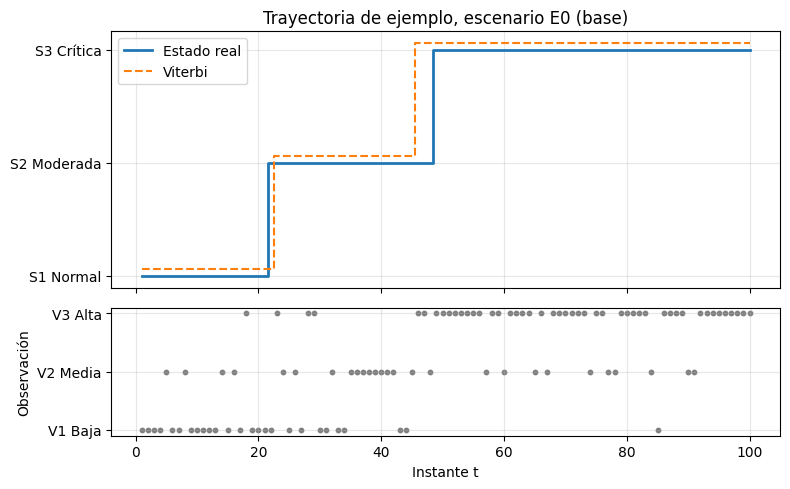

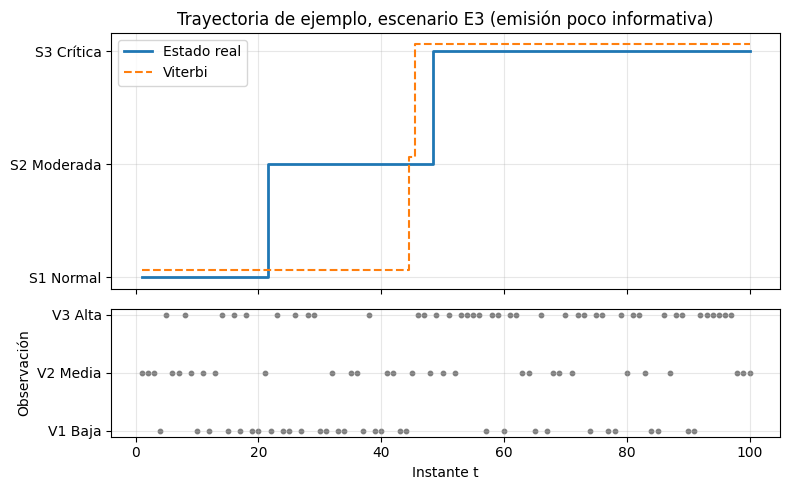

In [ ]:
def graficar_trayectoria(nombre, archivo, titulo):
    esc = ESCENARIOS[nombre]
    x, o = simular_replica(esc, CONFIG["T"], CONFIG["SEMILLA_BASE"])
    x_est, _ = viterbi(o, esc["A"], esc["B_dec"], esc["pi"])
    t = np.arange(1, CONFIG["T"] + 1)
    fig, ejes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ejes[0].step(t, x + 1, where="mid", label="Estado real", linewidth=2)
    ejes[0].step(t, x_est + 1 + 0.06, where="mid", linestyle="--", label="Viterbi", linewidth=1.5)
    ejes[0].set_yticks([1, 2, 3]); ejes[0].set_yticklabels(NOMBRES_ESTADOS)
    ejes[0].set_title(titulo); ejes[0].legend(loc="upper left")
    ejes[1].scatter(t, o + 1, s=10, color="gray")
    ejes[1].set_yticks([1, 2, 3]); ejes[1].set_yticklabels(NOMBRES_OBS)
    ejes[1].set_xlabel("Instante t"); ejes[1].set_ylabel("Observación")
    fig.tight_layout()
    fig.savefig(f"{CONFIG['CARPETA']}/{archivo}", dpi=CONFIG["DPI"])
    plt.show()

graficar_trayectoria("E0", "fig1_trayectoria_E0.png", "Trayectoria de ejemplo, escenario E0 (base)")
graficar_trayectoria("E3", "fig2_trayectoria_E3.png", "Trayectoria de ejemplo, escenario E3 (emisión poco informativa)")

## Celda 14. Figuras 3 y 4: alcance del estado crítico y tiempo hasta S3
- **Figura 3:** probabilidad de alcanzar S3 por escenario con IC de Wilson, y el valor teórico como marcador.
- **Figura 4:** distribución de τ en los escenarios con dinámica distinta (E0, E1, E2, E5). E3, E4 y E6 comparten las trayectorias de estados de E0, así que repetirlos no aporta información.

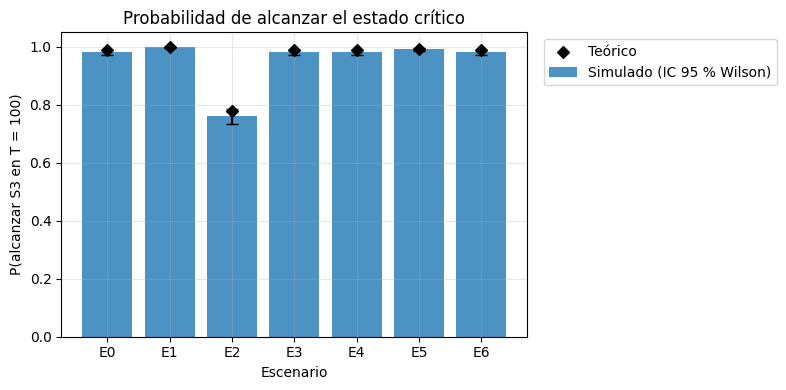

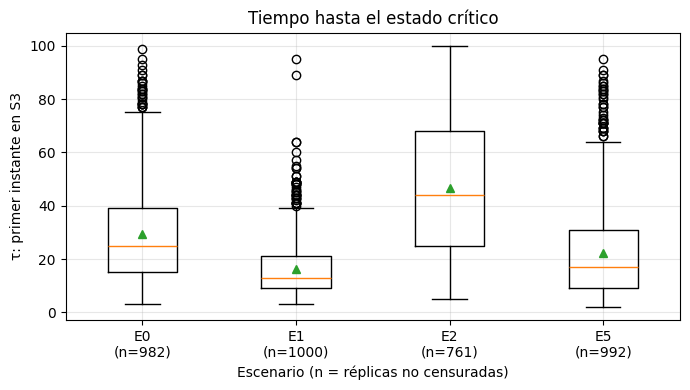

In [ ]:
# Figura 3
fig, ax = plt.subplots(figsize=(8, 4))
x_pos = np.arange(len(tabla_num))
p = tabla_num["p_crit"].values
err = [p - tabla_num["p_crit_inf"].values, tabla_num["p_crit_sup"].values - p]
ax.bar(x_pos, p, yerr=err, capsize=4, alpha=0.8, label="Simulado (IC 95 % Wilson)")
ax.scatter(x_pos, [TEORIA[n]["p_crit"] for n in tabla_num["escenario"]],
           color="black", marker="D", zorder=3, label="Teórico")
ax.set_xticks(x_pos); ax.set_xticklabels(tabla_num["escenario"]); ax.set_xlabel("Escenario")
ax.set_ylabel(f"P(alcanzar S3 en T = {CONFIG['T']})"); ax.set_ylim(0, 1.05)
ax.set_title("Probabilidad de alcanzar el estado crítico")
# Colocar la leyenda fuera del gráfico a la derecha
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout(); fig.savefig(f"{CONFIG['CARPETA']}/fig3_prob_critico.png", dpi=CONFIG["DPI"]); plt.show()

# Figura 4
esc_tau = ["E0", "E1", "E2", "E5"]
datos = [df[(df["escenario"] == n)]["tau"].dropna().values for n in esc_tau]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(datos, showmeans=True)
ax.set_xticklabels([f"{n}\n(n={len(d)})" for n, d in zip(esc_tau, datos)])
ax.set_xlabel("Escenario (n = réplicas no censuradas)")
ax.set_ylabel("τ: primer instante en S3")
ax.set_title("Tiempo hasta el estado crítico")
fig.tight_layout(); fig.savefig(f"{CONFIG['CARPETA']}/fig4_tiempo_critico.png", dpi=CONFIG["DPI"]); plt.show()

## Celda 15. Figuras 5 y 6: permanencia y exactitud de identificación
- **Figura 5:** frecuencia media de permanencia en cada estado real, por escenario (barras apiladas).
- **Figura 6:** exactitud de Viterbi global y por estado, con IC 95 %. La exactitud por estado muestra lo que la global puede ocultar, sobre todo en S3.

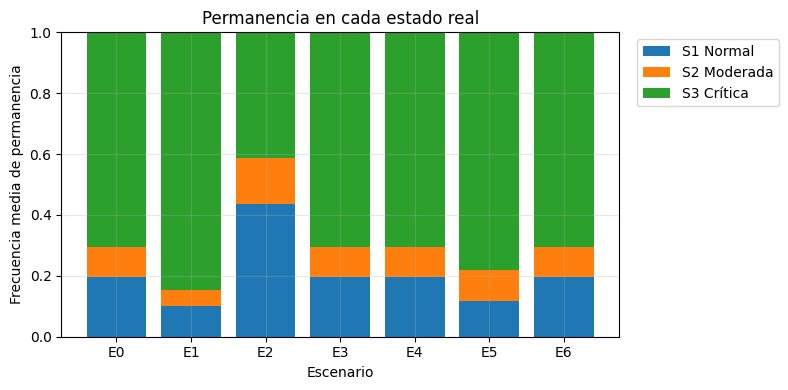

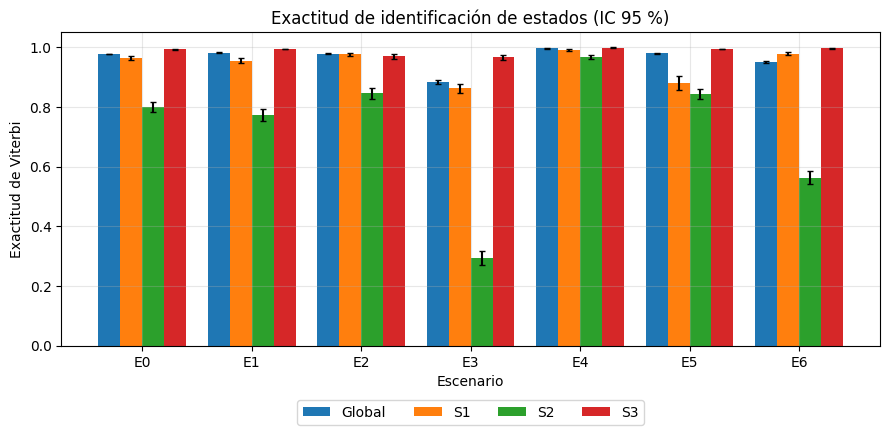

In [ ]:
# Figura 5
fig, ax = plt.subplots(figsize=(8, 4))
fondo = np.zeros(len(tabla_num))
for s in range(3):
    ax.bar(tabla_num["escenario"], tabla_num[f"freq_S{s+1}"], bottom=fondo, label=NOMBRES_ESTADOS[s])
    fondo += tabla_num[f"freq_S{s+1}"].values
ax.set_xlabel("Escenario"); ax.set_ylabel("Frecuencia media de permanencia"); ax.set_ylim(0, 1)
ax.set_title("Permanencia en cada estado real")
# Colocar la leyenda fuera del gráfico a la derecha
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.tight_layout(); fig.savefig(f"{CONFIG['CARPETA']}/fig5_permanencia.png", dpi=CONFIG["DPI"]); plt.show()

# Figura 6
fig, ax = plt.subplots(figsize=(9, 4.5))
columnas = ["acc_global", "acc_S1", "acc_S2", "acc_S3"]
etiquetas = ["Global", "S1", "S2", "S3"]
ancho = 0.2
x_pos = np.arange(len(tabla_num))
for i, (c, et) in enumerate(zip(columnas, etiquetas)):
    m = tabla_num[c].values
    err = [m - tabla_num[f"{c}_inf"].values, tabla_num[f"{c}_sup"].values - m]
    ax.bar(x_pos + (i - 1.5) * ancho, m, ancho, yerr=err, capsize=2, label=et)
ax.set_xticks(x_pos); ax.set_xticklabels(tabla_num["escenario"]); ax.set_xlabel("Escenario")
ax.set_ylabel("Exactitud de Viterbi"); ax.set_ylim(0, 1.05)
ax.set_title("Exactitud de identificación de estados (IC 95 %)")
# Colocar la leyenda debajo del gráfico de forma horizontal para evitar superposiciones
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout(); fig.savefig(f"{CONFIG['CARPETA']}/fig6_exactitud.png", dpi=CONFIG["DPI"]); plt.show()

## Celda 16. Figura 7: reproducibilidad entre semillas
Cada punto es la exactitud global media de una repetición completa (una semilla base). Si los puntos de cada escenario están muy juntos, el resultado no depende de la semilla.

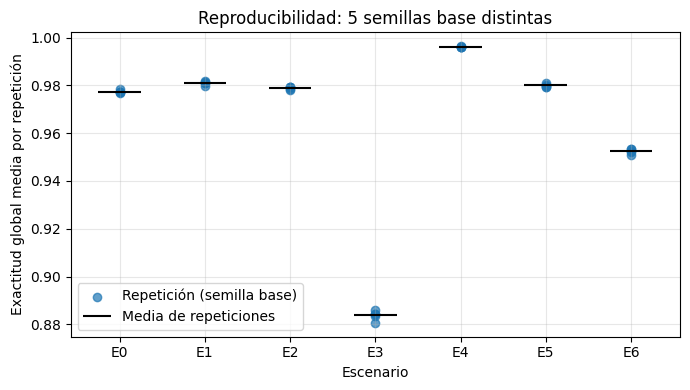

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
nombres = list(ESCENARIOS.keys())
for i, n in enumerate(nombres):
    vals = por_semilla[por_semilla["escenario"] == n]["acc_global"].values
    ax.scatter([i] * len(vals), vals, color="C0", alpha=0.7, label="Repetición (semilla base)" if i == 0 else None)
    ax.hlines(vals.mean(), i - 0.25, i + 0.25, color="black", label="Media de repeticiones" if i == 0 else None)
ax.set_xticks(range(len(nombres))); ax.set_xticklabels(nombres)
ax.set_xlabel("Escenario"); ax.legend(loc="lower left")
ax.set_ylabel("Exactitud global media por repetición")
ax.set_title(f"Reproducibilidad: {len(CONFIG['SEMILLAS_REPRO'])} semillas base distintas")
fig.tight_layout(); fig.savefig(f"{CONFIG['CARPETA']}/fig7_reproducibilidad.png", dpi=CONFIG["DPI"]); plt.show()